<a href="https://colab.research.google.com/github/mohamadnurtaufiq/UTS-Machine-Learning-kelompok-14/blob/main/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UTS Machine Learning — Task 2: Classification (Fraud Detection)





In [1]:
!pip -q install imbalanced-learn

In [2]:
# ============================================================
# UTS MACHINE LEARNING - TASK 2: CLASSIFICATION (FRAUD DETECTION)
# File input : klasifikasi_train.csv.gz, klasifikasi_test.csv.gz
# File output: prediksi_klasifikasi.csv
# ============================================================

# 0. INSTALLASI (jalankan sekali di Google Colab)
# !pip -q install imbalanced-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_score, recall_score, f1_score, confusion_matrix,
    classification_report
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42
REVIEW_COST = 25_000



In [3]:
# ------------------------------------------------------------
# 1. BACA DATASET (Langsung dari GitHub Kelompok 14)
# ------------------------------------------------------------
# Membaca dataset langsung menggunakan link RAW dari repositori GitHub Anda
TRAIN_PATH = "https://raw.githubusercontent.com/mohamadnurtaufiq/UTS-Machine-Learning-kelompok-14/main/dataset/klasifikasi_train.csv.gz"
TEST_PATH = "https://raw.githubusercontent.com/mohamadnurtaufiq/UTS-Machine-Learning-kelompok-14/main/dataset/klasifikasi_test.csv.gz"

# Pandas otomatis mendekompresi file .gz saat membaca via URL
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

print("Ukuran train:", train.shape)
print("Ukuran test :", test.shape)
print("Periode train:", train["waktu"].min(), "s.d.", train["waktu"].max())
print("Periode test :", test["waktu"].min(), "s.d.", test["waktu"].max())

Ukuran train: (403077, 85)
Ukuran test : (106674, 84)
Periode train: 2025-01-01 00:02:53 s.d. 2025-08-31 23:58:04
Periode test : 2025-09-01 00:01:51 s.d. 2025-10-31 23:57:22


In [4]:
# ------------------------------------------------------------
# 2. DATA AUDIT
# ------------------------------------------------------------
print("\\nDistribusi target:")
print(train["is_fraud"].value_counts())
print("\\nPersentase fraud:", round(train["is_fraud"].mean() * 100, 4), "%")
print("\\nMissing value terbanyak:")
print(train.isna().sum().sort_values(ascending=False).head(15))
print("\\nDuplikasi ID transaksi:", train["id_transaksi"].duplicated().sum())


\nDistribusi target:
is_fraud
0    400455
1      2622
Name: count, dtype: int64
\nPersentase fraud: 0.6505 %
\nMissing value terbanyak:
menit_sejak_trx_terakhir    102621
rasio_nominal_rata2         102621
id_pengguna                      0
waktu                            0
id_transaksi                     0
kanal                            0
tipe_perangkat                   0
nominal                          0
jam                              0
hari_libur                       0
umur_akun_hari                   0
level_kyc                        0
umur_pengguna_tahun              0
email_domain                     0
umur_perangkat_hari              0
dtype: int64
\nDuplikasi ID transaksi: 0


In [5]:
# ------------------------------------------------------------
# 3. FEATURE ENGINEERING DAN FEATURE AUDIT
# ------------------------------------------------------------
TARGET = "is_fraud"
ID_COL = "id_transaksi"

def buat_fitur(data):
    """Membuat fitur yang tersedia pada saat transaksi berlangsung."""
    df = data.copy()

    waktu = pd.to_datetime(df["waktu"], errors="coerce")
    df["bulan_transaksi"] = waktu.dt.month
    df["hari_dalam_minggu"] = waktu.dt.dayofweek
    df["akhir_pekan"] = (waktu.dt.dayofweek >= 5).astype("int8")

    # Fitur perilaku turunan dari riwayat transaksi yang sudah tersedia.
    df["rasio_trx_1j_24j"] = df["trx_1j"] / (df["trx_24j" ] + 1)
    df["rasio_trx_24j_7h"] = df["trx_24j"] / (df["trx_7h" ] + 1)
    df["nominal_per_trx_24j"] = df["nominal_24j"] / (df["trx_24j" ] + 1)

    # ID unik tidak digunakan langsung sebagai prediktor.
    # flag_review_manual dikeluarkan karena bisa merupakan informasi
    # yang muncul setelah transaksi ditinjau oleh tim risiko.
    kolom_dihapus = [
        "id_transaksi", "id_pengguna", "id_merchant",
        "waktu", "flag_review_manual", TARGET
    ]
    df = df.drop(columns=kolom_dihapus, errors="ignore")
    return df

X = buat_fitur(train)
y = train[TARGET].fillna(0).astype(int)
X_test = buat_fitur(test)

# Menyamakan kolom train dan test.
X_test = X_test.reindex(columns=X.columns)

kolom_kategori = X.select_dtypes(include=["object", "category"]).columns.tolist()
kolom_numerik = [c for c in X.columns if c not in kolom_kategori]

print("\nJumlah fitur:", X.shape[1])
print("Fitur kategori:", kolom_kategori)
print("Jumlah fitur numerik:", len(kolom_numerik))


Jumlah fitur: 85
Fitur kategori: ['kategori_merchant', 'kanal', 'tipe_perangkat', 'email_domain']
Jumlah fitur numerik: 81


In [6]:
# ------------------------------------------------------------
# 4. TIME-BASED SPLIT
# Train model: Januari-Mei 2025
# Calibration: Juni 2025
# Validation: Juli-Agustus 2025
# ------------------------------------------------------------
tanggal = pd.to_datetime(train["waktu"])
idx_model = tanggal < "2025-06-01"
idx_calib = (tanggal >= "2025-06-01") & (tanggal < "2025-07-01")
idx_valid = tanggal >= "2025-07-01"

X_model, y_model = X.loc[idx_model], y.loc[idx_model]
X_calib, y_calib = X.loc[idx_calib], y.loc[idx_calib]
X_valid, y_valid = X.loc[idx_valid], y.loc[idx_valid]
nominal_valid = train.loc[idx_valid, "nominal"].astype(float).to_numpy()

print("\\nJumlah data model:", len(X_model), "| fraud:", int(y_model.sum()))
print("Jumlah data kalibrasi:", len(X_calib), "| fraud:", int(y_calib.sum()))
print("Jumlah data validasi:", len(X_valid), "| fraud:", int(y_valid.sum()))

\nJumlah data model: 247464 | fraud: 1737
Jumlah data kalibrasi: 50375 | fraud: 299
Jumlah data validasi: 105238 | fraud: 586


In [7]:
# ------------------------------------------------------------
# 5. PREPROCESSING
# ------------------------------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False))
        ]), kolom_numerik),
        ("kategori", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), kolom_kategori)
    ],
    remainder="drop"
)

In [8]:
# ------------------------------------------------------------
# 6. TIGA PENDEKATAN UNTUK DATA IMBALANCED
# A. Logistic Regression + class weighting
# B. Random Forest + class weighting
# C. Logistic Regression + random undersampling
# ------------------------------------------------------------
model_dict = {
    "LogisticRegression_ClassWeight": Pipeline(steps=[
        ("prep", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=700,
            solver="saga",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),

    "RandomForest_ClassWeight": Pipeline(steps=[
        ("prep", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=120,
            max_depth=16,
            min_samples_leaf=8,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),

    "LogisticRegression_Undersampling": ImbPipeline(steps=[
        ("prep", preprocessor),
        ("sampling", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", LogisticRegression(
            max_iter=700,
            solver="saga",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}

In [9]:
# ------------------------------------------------------------
# 7. KALIBRASI PROBABILITAS (PLATT / SIGMOID CALIBRATION)
# Model dilatih pada Jan-Mei, kalibrator pada Juni,
# lalu dievaluasi pada Juli-Agustus.
# ------------------------------------------------------------
def probabilitas_mentah(model, data):
    return model.predict_proba(data)[:, 1]

def latih_kalibrator(prob, label):
    # Kalibrasi sigmoid menggunakan log-odds probabilitas model.
    eps = 1e-6
    p = np.clip(np.asarray(prob), eps, 1 - eps)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    kalibrator = LogisticRegression(solver="lbfgs")
    kalibrator.fit(logit, np.asarray(label))
    return kalibrator

def terapkan_kalibrator(kalibrator, prob):
    eps = 1e-6
    p = np.clip(np.asarray(prob), eps, 1 - eps)
    logit = np.log(p / (1 - p)).reshape(-1, 1)
    return kalibrator.predict_proba(logit)[:, 1]

hasil_model = {}
prob_validasi = {}
ringkasan = []

for nama, model in model_dict.items():
    print("\\nMelatih model:", nama)
    model.fit(X_model, y_model)

    prob_calib = probabilitas_mentah(model, X_calib)
    kalibrator = latih_kalibrator(prob_calib, y_calib)

    prob_val_raw = probabilitas_mentah(model, X_valid)
    prob_val = terapkan_kalibrator(kalibrator, prob_val_raw)

    hasil_model[nama] = {
        "model": model,
        "kalibrator": kalibrator
    }
    prob_validasi[nama] = prob_val

    ringkasan.append({
        "model": nama,
        "PR_AUC": average_precision_score(y_valid, prob_val),
        "ROC_AUC": roc_auc_score(y_valid, prob_val),
        "Brier_Score": brier_score_loss(y_valid, prob_val)
    })

tabel_model = pd.DataFrame(ringkasan).sort_values(
    "PR_AUC", ascending=False
)
print("\\nPerbandingan model:")
print(tabel_model.to_string(index=False))

\nMelatih model: LogisticRegression_ClassWeight
\nMelatih model: RandomForest_ClassWeight
\nMelatih model: LogisticRegression_Undersampling
\nPerbandingan model:
                           model   PR_AUC  ROC_AUC  Brier_Score
        RandomForest_ClassWeight 0.401760 0.952455     0.004019
LogisticRegression_Undersampling 0.331230 0.920422     0.004350
  LogisticRegression_ClassWeight 0.306098 0.924947     0.004482


In [10]:
# ------------------------------------------------------------
# 8. THRESHOLD TUNING BERDASARKAN BIAYA
# Biaya review = Rp25.000 per transaksi yang ditandai.
# Fraud yang tidak ditandai menyebabkan kerugian sebesar nominal.
# ------------------------------------------------------------
def hitung_biaya(label, probabilitas, nominal, threshold):
    label = np.asarray(label)
    probabilitas = np.asarray(probabilitas)
    nominal = np.asarray(nominal)

    ditandai = probabilitas >= threshold
    fraud_lolos = (label == 1) & (~ditandai)

    biaya_fraud_lolos = nominal[fraud_lolos].sum()
    biaya_review = ditandai.sum() * REVIEW_COST
    total = biaya_fraud_lolos + biaya_review

    return {
        "threshold": float(threshold),
        "jumlah_ditandai": int(ditandai.sum()),
        "fraud_lolos": int(fraud_lolos.sum()),
        "biaya_fraud_lolos": float(biaya_fraud_lolos),
        "biaya_review": float(biaya_review),
        "total_biaya": float(total)
    }

grid_threshold = np.unique(np.r_[
    np.linspace(0.001, 0.10, 100),
    np.linspace(0.11, 0.99, 45)
])

hasil_biaya = {}
for nama, prob in prob_validasi.items():
    kandidat = [
        hitung_biaya(y_valid, prob, nominal_valid, t)
        for t in grid_threshold
    ]
    hasil_biaya[nama] = min(kandidat, key=lambda x: x["total_biaya"])

tabel_biaya = pd.DataFrame(hasil_biaya).T.sort_values("total_biaya")
print("\\nPerbandingan biaya validasi:")
print(tabel_biaya.to_string())

# Pilih model dengan total biaya validasi terendah.
model_terpilih = tabel_biaya.index[0]
threshold_terpilih = hasil_biaya[model_terpilih]["threshold"]
prob_terpilih = prob_validasi[model_terpilih]

print("\\nModel terpilih:", model_terpilih)
print("Threshold terpilih:", threshold_terpilih)
print("Rincian biaya:", hasil_biaya[model_terpilih])

\nPerbandingan biaya validasi:
                                  threshold  jumlah_ditandai  fraud_lolos  biaya_fraud_lolos  biaya_review  total_biaya
RandomForest_ClassWeight              0.019           2461.0        171.0        142614500.0    61525000.0  204139500.0
LogisticRegression_Undersampling      0.034           2347.0        220.0        173324800.0    58675000.0  231999800.0
LogisticRegression_ClassWeight        0.024           3052.0        201.0        160154500.0    76300000.0  236454500.0
\nModel terpilih: RandomForest_ClassWeight
Threshold terpilih: 0.019000000000000003
Rincian biaya: {'threshold': 0.019000000000000003, 'jumlah_ditandai': 2461, 'fraud_lolos': 171, 'biaya_fraud_lolos': 142614500.0, 'biaya_review': 61525000.0, 'total_biaya': 204139500.0}


In [11]:
# ------------------------------------------------------------
# 9. EVALUASI MODEL TERPILIH
# ------------------------------------------------------------
pred_valid = (prob_terpilih >= threshold_terpilih).astype(int)

print("\\nClassification report:")
print(classification_report(
    y_valid, pred_valid, digits=4, zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_valid, pred_valid))
print("Precision:", precision_score(y_valid, pred_valid, zero_division=0))
print("Recall   :", recall_score(y_valid, pred_valid, zero_division=0))
print("F1       :", f1_score(y_valid, pred_valid, zero_division=0))
print("PR-AUC   :", average_precision_score(y_valid, prob_terpilih))
print("Brier    :", brier_score_loss(y_valid, prob_terpilih))

\nClassification report:
              precision    recall  f1-score   support

           0     0.9983    0.9804    0.9893    104652
           1     0.1686    0.7082    0.2724       586

    accuracy                         0.9789    105238
   macro avg     0.5835    0.8443    0.6309    105238
weighted avg     0.9937    0.9789    0.9853    105238

Confusion matrix:
[[102606   2046]
 [   171    415]]
Precision: 0.16863063795205202
Recall   : 0.7081911262798635
F1       : 0.272399081063341
PR-AUC   : 0.4017596993927921
Brier    : 0.004019000384144282


\nRingkasan fraud per bulan:
  bulan  jumlah_transaksi  jumlah_fraud  fraud_rate  median_nominal
2025-01             50432           327    0.006484        128950.0
2025-02             46240           301    0.006510        129600.0
2025-03             51048           387    0.007581        129800.0
2025-04             47413           355    0.007487        127300.0
2025-05             52331           367    0.007013        127600.0
2025-06             50375           299    0.005935        127500.0
2025-07             52334           341    0.006516        126900.0
2025-08             52904           245    0.004631        128300.0


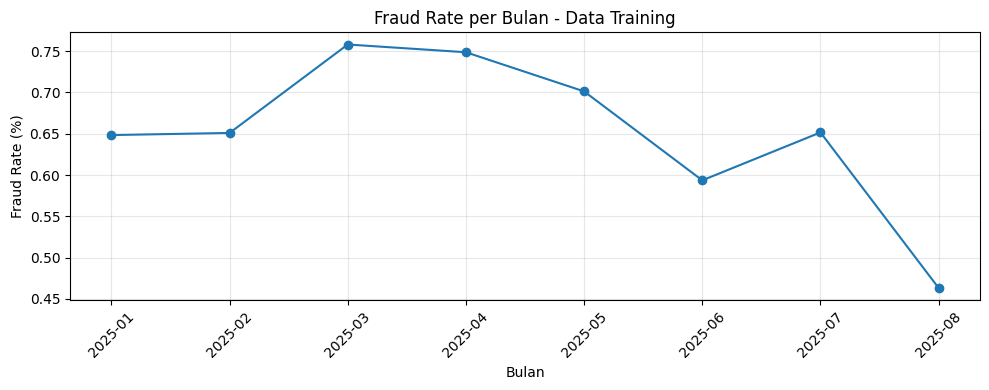

\nFraud rate berdasarkan kanal:
           count  sum      mean
kanal                          
kartu      49517  840  0.016964
web        24842  419  0.016867
va         59921  537  0.008962
aplikasi  179979  642  0.003567
qris       88818  184  0.002072
\nFraud rate berdasarkan kategori merchant:
                   count  sum      mean
kategori_merchant                      
voucher_game       18016  427  0.023701
emas                6404  150  0.023423
gadget             17033  281  0.016497
top_up_ewallet     20815  232  0.011146
toko_online        32649  315  0.009648
pulsa_data         38660  308  0.007967
kecantikan         16917  123  0.007271
fashion            27573  196  0.007108
elektronik         44032  299  0.006791
jasa_lainnya        8223   47  0.005716
pendidikan          2750    8  0.002909
olahraga            5155   12  0.002328
tagihan_listrik    14972   31  0.002071
tagihan_air         4885   10  0.002047
tiket_perjalanan   10748   20  0.001861
rumah_tangga       1

In [12]:
# ------------------------------------------------------------
# 10. ANALISIS PERUBAHAN POLA FRAUD (PATTERN SHIFT)
# Hanya bisa dihitung pada data train karena test tidak memiliki label.
# ------------------------------------------------------------
analisis_bulan = train.copy()
analisis_bulan["bulan"] = pd.to_datetime(
    analisis_bulan["waktu"]
).dt.to_period("M").astype(str)

ringkasan_bulan = analisis_bulan.groupby("bulan").agg(
    jumlah_transaksi=("is_fraud", "size"),
    jumlah_fraud=("is_fraud", "sum"),
    fraud_rate=("is_fraud", "mean"),
    median_nominal=("nominal", "median")
).reset_index()

print("\\nRingkasan fraud per bulan:")
print(ringkasan_bulan.to_string(index=False))

plt.figure(figsize=(10, 4))
plt.plot(
    ringkasan_bulan["bulan"],
    ringkasan_bulan["fraud_rate"] * 100,
    marker="o"
)
plt.title("Fraud Rate per Bulan - Data Training")
plt.xlabel("Bulan")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Analisis ringkas per kanal dan kategori merchant.
print("\\nFraud rate berdasarkan kanal:")
print(
    train.groupby("kanal")["is_fraud"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

print("\\nFraud rate berdasarkan kategori merchant:")
print(
    train.groupby("kategori_merchant")["is_fraud"]
    .agg(["count", "sum", "mean"])
    .sort_values("mean", ascending=False)
)

In [13]:
# ------------------------------------------------------------
# 11. MODEL FINAL UNTUK DATA TEST
# Fit model terpilih pada Januari-Juni.
# Kalibrasi pada Juli.
# Threshold ditentukan pada Agustus.
# ------------------------------------------------------------
tanggal = pd.to_datetime(train["waktu"])
idx_final_fit = tanggal < "2025-07-01"
idx_final_calib = (tanggal >= "2025-07-01") & (tanggal < "2025-08-01")
idx_final_threshold = tanggal >= "2025-08-01"

X_final_fit = X.loc[idx_final_fit]
y_final_fit = y.loc[idx_final_fit]
X_final_calib = X.loc[idx_final_calib]
y_final_calib = y.loc[idx_final_calib]
X_final_threshold = X.loc[idx_final_threshold]
y_final_threshold = y.loc[idx_final_threshold]
nominal_final_threshold = train.loc[
    idx_final_threshold, "nominal"
].astype(float).to_numpy()

# Buat ulang model terpilih dengan konfigurasi yang sama.
final_model = model_dict[model_terpilih]
final_model.fit(X_final_fit, y_final_fit)

prob_calib_final_raw = probabilitas_mentah(final_model, X_final_calib)
final_calibrator = latih_kalibrator(
    prob_calib_final_raw, y_final_calib
)

prob_threshold_raw = probabilitas_mentah(
    final_model, X_final_threshold
)
prob_threshold = terapkan_kalibrator(
    final_calibrator, prob_threshold_raw
)

# Cari threshold final hanya pada periode Agustus.
kandidat_final = [
    hitung_biaya(
        y_final_threshold,
        prob_threshold,
        nominal_final_threshold,
        t
    )
    for t in grid_threshold
]
threshold_final = min(
    kandidat_final, key=lambda x: x["total_biaya"]
)["threshold"]

print("\\nThreshold final dari validasi Agustus:", threshold_final)

# Prediksi data test September-Oktober 2025.
prob_test_raw = probabilitas_mentah(final_model, X_test)
prob_test = terapkan_kalibrator(final_calibrator, prob_test_raw)
tandai_test = (prob_test >= threshold_final).astype(int)

submission = pd.DataFrame({
    "id_transaksi": test[ID_COL],
    "prob": prob_test,
    "tandai": tandai_test
})

OUTPUT_PATH = "/content/prediksi_klasifikasi.csv"
submission.to_csv(OUTPUT_PATH, index=False)

\nThreshold final dari validasi Agustus: 0.094


In [14]:
# ------------------------------------------------------------
# 12. VALIDASI FORMAT OUTPUT
# ------------------------------------------------------------
hasil_cek = pd.read_csv(OUTPUT_PATH)

assert list(hasil_cek.columns) == [
    "id_transaksi", "prob", "tandai"
]
assert len(hasil_cek) == len(test)
assert hasil_cek["prob"].between(0, 1).all()
assert set(hasil_cek["tandai"].unique()).issubset({0, 1})
assert hasil_cek["id_transaksi"].equals(test["id_transaksi"])

print("\\nBERHASIL membuat:", OUTPUT_PATH)
print("Jumlah baris:", len(hasil_cek))
print("Jumlah transaksi ditandai:", int(hasil_cek["tandai"].sum()))
print("\\nContoh hasil:")
print(hasil_cek.head())

# Di Google Colab, jalankan sel berikut untuk mengunduh file:
# from google.colab import files
# files.download("prediksi_klasifikasi.csv")

\nBERHASIL membuat: /content/prediksi_klasifikasi.csv
Jumlah baris: 106674
Jumlah transaksi ditandai: 804
\nContoh hasil:
  id_transaksi      prob  tandai
0   T502861791  0.012542       0
1   T980390558  0.000479       0
2   T657838379  0.000662       0
3   T985886276  0.001932       0
4   T852019235  0.001445       0


In [15]:

# ==========================================
# EXPORT HASIL PREDIKSI KE EXCEL YANG RAPI
# ==========================================

from google.colab import files
from openpyxl.styles import Font, PatternFill, Alignment

# Membuat tabel hasil prediksi
hasil_rapi = submission.copy()

hasil_rapi["Probabilitas Fraud (%)"] = (
    hasil_rapi["prob"] * 100
)

hasil_rapi["Keputusan"] = hasil_rapi["tandai"].map({
    0: "Tidak Perlu Review",
    1: "Perlu Review"
})

hasil_rapi = hasil_rapi[
    ["id_transaksi", "Probabilitas Fraud (%)", "Keputusan"]
]

hasil_rapi = hasil_rapi.rename(columns={
    "id_transaksi": "ID Transaksi"
})

# Membuat ringkasan
ringkasan = pd.DataFrame({
    "Keterangan": [
        "Total Transaksi",
        "Perlu Review",
        "Tidak Perlu Review",
        "Threshold",
        "Biaya Review"
    ],
    "Nilai": [
        len(submission),
        int((submission["tandai"] == 1).sum()),
        int((submission["tandai"] == 0).sum()),
        threshold_final,
        REVIEW_COST
    ]
})

# Simpan ke Excel
nama_file = "/content/Hasil_Prediksi_Fraud.xlsx"

with pd.ExcelWriter(nama_file, engine="openpyxl") as writer:
    hasil_rapi.to_excel(
        writer, sheet_name="Hasil Prediksi", index=False
    )
    ringkasan.to_excel(
        writer, sheet_name="Ringkasan", index=False
    )

# Mengatur tampilan Excel
from openpyxl import load_workbook

wb = load_workbook(nama_file)
ws = wb["Hasil Prediksi"]

header_fill = PatternFill("solid", fgColor="263B5A")

for cell in ws[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = header_fill
    cell.alignment = Alignment(horizontal="center")

ws.column_dimensions["A"].width = 22
ws.column_dimensions["B"].width = 25
ws.column_dimensions["C"].width = 28
ws.freeze_panes = "A2"
ws.auto_filter.ref = ws.dimensions

for row in range(2, ws.max_row + 1):
    ws.cell(row, 2).number_format = '0.00"%"'

    if ws.cell(row, 3).value == "Perlu Review":
        ws.cell(row, 3).fill = PatternFill(
            "solid", fgColor="FCE4D6"
        )
    else:
        ws.cell(row, 3).fill = PatternFill(
            "solid", fgColor="E2F0D9"
        )

# Format ringkasan
ws2 = wb["Ringkasan"]
ws2.column_dimensions["A"].width = 30
ws2.column_dimensions["B"].width = 22

for cell in ws2[1]:
    cell.font = Font(bold=True, color="FFFFFF")
    cell.fill = header_fill

wb.save(nama_file)

print("Excel berhasil dibuat!")

# Download otomatis
files.download(nama_file)


Excel berhasil dibuat!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>